# Stage 8 – K-Means clustering

**Purpose.** Inside each environment, find groups of segments that are driven in a similar way
(for example "slow, stop-and-go" vs "faster, flowing" urban driving). Stage 9 will then pick real
example segments from each group, and Stage 10 will build the driving cycles from them.

**Important.** K-Means groups similar *feature vectors* (numbers). It does **not** build a driving
cycle and does not create a speed–time trace. A cluster centre is an average of numbers, not a real
drive. Real segments are picked in Stage 9.

**Approach.**
1. **Choose the features.** Start from the Stage 7 clustering candidates, remove redundant ones
   (|r| ≥ 0.9) and unstable ones. Identifiers, environment labels, times and coordinates are never used.
2. **Prepare.** Log-transform skewed features, scale every feature to mean 0 / SD 1 so no unit
   dominates, and clip extreme values at ±3 SD so a few outliers cannot pull a cluster.
3. **Cluster each environment separately** (the methodology's candidate approach). A check on the whole
   dataset shows why: a single clustering mostly re-discovers the environments.
4. **Choose k** using the elbow method and the silhouette score, rejecting any k that creates tiny clusters.
5. **Check quality:** separation (silhouette, Davies–Bouldin), stability (bootstrap and different
   random seeds), sensitivity to outliers, and cluster sizes.

**Output.** `intermediate/stage8_clusters/segment_clusters.csv` (cluster per segment, input of Stage 9),
plus k-selection, cluster summary, cluster quality, figures and the saved model in `outputs/stage8_clustering/`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

BASE = Path("/content/drive/MyDrive/Colab Notebooks/Component01")
FEATURES = BASE / "intermediate/stage7_features/segment_features.csv"       # Stage 7 feature table
DEFINITIONS = BASE / "outputs/stage7_features/feature_definitions.csv"      # Stage 7 feature definitions
OUT_DIR = BASE / "intermediate/stage8_clusters"                             # cluster per segment = input of Stage 9
REPORT_DIR = BASE / "outputs/stage8_clustering"                             # k selection, summaries, stability, figures
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not FEATURES.exists():
    raise FileNotFoundError(f"{FEATURES} not found. Is Google Drive mounted, and has Stage 7 been run?")
features = pd.read_csv(FEATURES)
definitions = pd.read_csv(DEFINITIONS)
print(f"{len(features):,} segments with features | per environment: {features['environment'].value_counts().to_dict()}")

1,021 segments with features | per environment: {'Urban': 734, 'Expressway': 160, 'Suburban': 127}


In [2]:
CFG = {
    # --- which environments are clustered
    "min_segments_per_env": 30,       # fewer segments than this -> no clustering (too little data)
    # --- feature selection
    "replace": {"stops_per_km": "stops_per_min"},   # stops/km explodes on very short segments (Stage 7) -> use stops/min
    "drop_compositional": ["decel_share"],          # idle + accel + decel + cruise = 1, so one share is redundant
    "max_abs_corr": 0.9,              # of two features with |r| >= 0.9, the less preferred one is dropped
    "preferred_order": ["mean_speed_kmh", "std_speed_kmh", "std_accel_ms2", "rpa_ms2", "idle_share",
                        "cruise_share", "accel_share", "stops_per_min", "mean_pos_accel_ms2",
                        "mean_neg_accel_ms2", "duration_s", "distance_km", "max_speed_kmh",
                        "mean_moving_speed_kmh", "pke_ms2"],
    "log_features": ["duration_s", "distance_km"],  # strongly right-skewed -> log(1 + x) before scaling
    "clip_z": 3.0,                    # after standard scaling, values beyond +/-3 SD are clipped (limits outlier pull)
    # --- choosing k
    "k_range": (2, 8),
    "min_cluster_share": 0.05,        # a k is only accepted if every cluster holds >= 5 % of the segments ...
    "min_cluster_size": 10,           # ... and at least 10 segments (Stage 9 needs real examples per cluster)
    "n_init": 20,                     # K-Means restarts per fit (best of 20 is kept)
    "random_state": 42,
    # --- stability
    "n_bootstrap": 30,                # refits on random 80 % subsamples
    "subsample": 0.8,
    "stable_ari": 0.8,                # mean adjusted Rand index >= 0.8 -> stable clusters
}
pd.Series(CFG, name="value").to_frame()

,value
min_segments_per_env,30
replace,{'stops_per_km': 'stops_per_min'}
drop_compositional,[decel_share]
max_abs_corr,0.9
preferred_order,"[mean_speed_kmh, std_speed_kmh, std_accel_ms2,..."
log_features,"[duration_s, distance_km]"
clip_z,3.0
k_range,"(2, 8)"
min_cluster_share,0.05
min_cluster_size,10


In [3]:
# 1. start from the clustering candidates marked in Stage 7
cand = definitions.loc[definitions["clustering_candidate"], "feature"].tolist()
cand = [CFG["replace"].get(c, c) for c in cand]
log = []
for c in CFG["drop_compositional"]:
    if c in cand:
        cand.remove(c)
        log.append((c, "dropped", "shares of idle / accel / decel / cruise add up to 1 - one of them is redundant"))
for old, new in CFG["replace"].items():
    log.append((new, "replaces " + old, "stops per km becomes extreme on very short segments (up to 64 / km)"))

# 2. drop redundant features: walk through the preferred order. A feature is dropped only if it duplicates
#    a feature already kept (|r| >= max_abs_corr) in EVERY clustered environment. If it adds information in
#    at least one environment (e.g. stops matter in Urban even if they are ~0 on the Expressway), it is kept.
envs_all = [e for e in features["environment"].unique()
            if (features["environment"] == e).sum() >= CFG["min_segments_per_env"]]
rank = {c: i for i, c in enumerate(CFG["preferred_order"])}
cand = sorted(cand, key=lambda c: rank.get(c, 99))
kept = []
for c in cand:
    dropped = False
    for k in kept:
        r = {e: abs(features.loc[features["environment"] == e, [c, k]].corr().iat[0, 1]) for e in envs_all}
        r = {e: (0.0 if np.isnan(v) else v) for e, v in r.items()}
        high = [e for e, v in r.items() if v >= CFG["max_abs_corr"]]
        if len(high) == len(envs_all):
            log.append((c, "dropped", f"|r| >= {CFG['max_abs_corr']} with {k} in every environment "
                                      f"(lowest {min(r.values()):.2f})"))
            dropped = True
            break
        if high:
            log.append((c, "kept", f"|r| >= {CFG['max_abs_corr']} with {k} only in {', '.join(high)} - "
                                   "adds information elsewhere"))
    if not dropped:
        kept.append(c)
FEATS = kept

# 3. the clustering matrix must contain only driving behaviour
forbidden = {"seg_uid", "trip_id", "route", "environment", "quality", "start_time", "start_reason", "end_reason"}
assert not set(FEATS) & forbidden and not any("lat" in c or "lon" in c for c in FEATS)

selection = pd.DataFrame(log, columns=["feature", "decision", "reason"])
selection.to_csv(REPORT_DIR / "feature_selection_log.csv", index=False)
display(selection)
print(f"{len(FEATS)} clustering features:", FEATS)

,feature,decision,reason
0,decel_share,dropped,shares of idle / accel / decel / cruise add up...
1,stops_per_min,replaces stops_per_km,stops per km becomes extreme on very short seg...
2,idle_share,kept,|r| >= 0.9 with rpa_ms2 only in Expressway - a...
3,cruise_share,kept,|r| >= 0.9 with mean_speed_kmh only in Express...
4,stops_per_min,kept,|r| >= 0.9 with rpa_ms2 only in Expressway - a...
5,stops_per_min,kept,|r| >= 0.9 with idle_share only in Expressway ...
6,distance_km,kept,|r| >= 0.9 with mean_speed_kmh only in Express...
7,distance_km,kept,"|r| >= 0.9 with duration_s only in Urban, Expr..."
8,max_speed_kmh,kept,|r| >= 0.9 with mean_speed_kmh only in Express...
9,max_speed_kmh,kept,|r| >= 0.9 with duration_s only in Expressway ...


14 clustering features: ['mean_speed_kmh', 'std_speed_kmh', 'std_accel_ms2', 'rpa_ms2', 'idle_share', 'cruise_share', 'accel_share', 'stops_per_min', 'mean_pos_accel_ms2', 'mean_neg_accel_ms2', 'duration_s', 'distance_km', 'max_speed_kmh', 'mean_moving_speed_kmh']


In [4]:
def prepare(df):
    """Feature matrix for K-Means: log for skewed features, standard scaling, clipping at +/- clip_z."""
    X = df[FEATS].astype(float).copy()
    for c in CFG["log_features"]:
        if c in X:
            X[c] = np.log1p(X[c])
    scaler = StandardScaler().fit(X)
    Z = np.clip(scaler.transform(X), -CFG["clip_z"], CFG["clip_z"])
    return Z, scaler


def fit_kmeans(Z, k, seed=CFG["random_state"]):
    return KMeans(n_clusters=k, n_init=CFG["n_init"], random_state=seed).fit(Z)


def knee(ks, inertia):
    """Elbow point: the k farthest from the straight line joining the first and last inertia values."""
    x, y = np.asarray(ks, float), np.asarray(inertia, float)
    if len(x) < 3:
        return int(x[0])
    x_n, y_n = (x - x[0]) / (x[-1] - x[0]), (y - y[-1]) / (y[0] - y[-1])
    return int(x[np.argmax(np.abs(1 - x_n - y_n))])


def evaluate_k(Z):
    n = len(Z)
    rows = []
    for k in range(CFG["k_range"][0], min(CFG["k_range"][1], n // CFG["min_cluster_size"]) + 1):
        km = fit_kmeans(Z, k)
        sizes = np.bincount(km.labels_, minlength=k)
        rows.append({"k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(Z, km.labels_),
                     "davies_bouldin": davies_bouldin_score(Z, km.labels_),
                     "smallest_cluster": int(sizes.min()), "smallest_share": sizes.min() / n,
                     "acceptable": bool(sizes.min() >= max(CFG["min_cluster_size"], CFG["min_cluster_share"] * n))})
    return pd.DataFrame(rows)


def choose_k(t):
    """Highest silhouette among acceptable k (no tiny clusters); elbow k reported for comparison."""
    ok = t[t["acceptable"]]
    k_sil = int(ok.loc[ok["silhouette"].idxmax(), "k"]) if len(ok) else int(t["k"].min())
    return k_sil, knee(t["k"], t["inertia"])


def stability(Z, k, labels):
    """Mean ARI between the final labels and (a) refits on 80 % subsamples, (b) other random seeds."""
    rng = np.random.default_rng(CFG["random_state"])
    boot = []
    for _ in range(CFG["n_bootstrap"]):
        idx = rng.choice(len(Z), int(CFG["subsample"] * len(Z)), replace=False)
        km = KMeans(n_clusters=k, n_init=CFG["n_init"], random_state=int(rng.integers(1e6))).fit(Z[idx])
        boot.append(adjusted_rand_score(labels, km.predict(Z)))
    seeds = [adjusted_rand_score(labels, fit_kmeans(Z, k, seed=s).labels_) for s in (1, 2, 3, 4, 5)]
    return float(np.mean(boot)), float(np.min(boot)), float(np.mean(seeds))

In [5]:
envs = [e for e in ["Urban", "Suburban", "Intercity", "Rural", "Expressway"] if e in envs_all]
skipped = sorted(set(features["environment"]) - set(envs))
for e in skipped:
    print(f"{e}: {(features['environment'] == e).sum()} segments < {CFG['min_segments_per_env']} -> not clustered")
for e in ["Urban", "Suburban", "Intercity", "Rural", "Expressway"]:
    if e not in set(features["environment"]):
        print(f"{e}: no segments in the data -> not clustered (coverage limitation)")

results, k_tables, assignments = {}, [], []
for e in envs:
    df = features[features["environment"] == e].reset_index(drop=True)
    Z, scaler = prepare(df)
    t = evaluate_k(Z)
    k_sil, k_elbow = choose_k(t)
    km = fit_kmeans(Z, k_sil)
    # renumber clusters by mean speed (cluster 1 = slowest) so the numbers mean the same thing every run
    order_ = np.argsort([df.loc[km.labels_ == c, "mean_speed_kmh"].mean() for c in range(k_sil)])
    remap = {old: new + 1 for new, old in enumerate(order_)}
    labels = np.array([remap[l] for l in km.labels_])
    dist = np.linalg.norm(Z - km.cluster_centers_[km.labels_], axis=1)
    sil = silhouette_samples(Z, labels)
    ari_boot, ari_min, ari_seed = stability(Z, k_sil, km.labels_)
    # outlier sensitivity: same k without clipping
    Xn = df[FEATS].astype(float).copy()
    for c in CFG["log_features"]:
        if c in Xn:
            Xn[c] = np.log1p(Xn[c])
    Zn = scaler.transform(Xn)
    ari_noclip = adjusted_rand_score(km.labels_, fit_kmeans(Zn, k_sil).labels_)
    t.insert(0, "environment", e)
    t["chosen"] = t["k"] == k_sil
    k_tables.append(t)
    results[e] = {"n": len(df), "k": k_sil, "k_elbow": k_elbow,
                  "silhouette": float(t.loc[t["k"] == k_sil, "silhouette"].iat[0]),
                  "davies_bouldin": float(t.loc[t["k"] == k_sil, "davies_bouldin"].iat[0]),
                  "ari_bootstrap_mean": ari_boot, "ari_bootstrap_min": ari_min, "ari_seeds": ari_seed,
                  "ari_without_clipping": ari_noclip,
                  "Z": Z, "labels": labels, "centers": km.cluster_centers_[order_], "df": df,
                  "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist()}
    assignments.append(df[["seg_uid", "trip_id", "route", "environment", "quality"]].assign(
        cluster=labels, cluster_id=[f"{e[:3].upper()}-C{l}" for l in labels],
        dist_to_centroid=np.round(dist, 4), silhouette=np.round(sil, 4)))
    print(f"{e:10s}: {len(df):4d} segments -> k = {k_sil} (silhouette choice), elbow suggests k = {k_elbow}")

k_table = pd.concat(k_tables, ignore_index=True).round(4)
k_table.to_csv(REPORT_DIR / "k_selection.csv", index=False)
clusters = pd.concat(assignments, ignore_index=True)
clusters.to_csv(OUT_DIR / "segment_clusters.csv", index=False)
k_table

Intercity: no segments in the data -> not clustered (coverage limitation)
Rural: no segments in the data -> not clustered (coverage limitation)
Urban     :  734 segments -> k = 2 (silhouette choice), elbow suggests k = 4
Suburban  :  127 segments -> k = 3 (silhouette choice), elbow suggests k = 5
Expressway:  160 segments -> k = 3 (silhouette choice), elbow suggests k = 4


,environment,k,inertia,silhouette,davies_bouldin,smallest_cluster,smallest_share,acceptable,chosen
0,Urban,2,6801.4788,0.3316,1.2717,218,0.2970,True,True
1,Urban,3,5269.0990,0.2820,1.2379,163,0.2221,True,False
2,Urban,4,4607.6067,0.2394,1.3377,118,0.1608,True,False
3,Urban,5,4035.0414,0.2676,1.1941,48,0.0654,True,False
4,Urban,6,3595.6619,0.2593,1.2015,48,0.0654,True,False
5,Urban,7,3322.2046,0.2288,1.2808,47,0.0640,True,False
6,Urban,8,3119.9924,0.2254,1.3044,45,0.0613,True,False
7,Suburban,2,1098.1055,0.3566,1.1824,54,0.4252,True,False
8,Suburban,3,817.6499,0.3881,1.0969,22,0.1732,True,True
9,Suburban,4,687.2685,0.3622,1.1569,10,0.0787,True,False


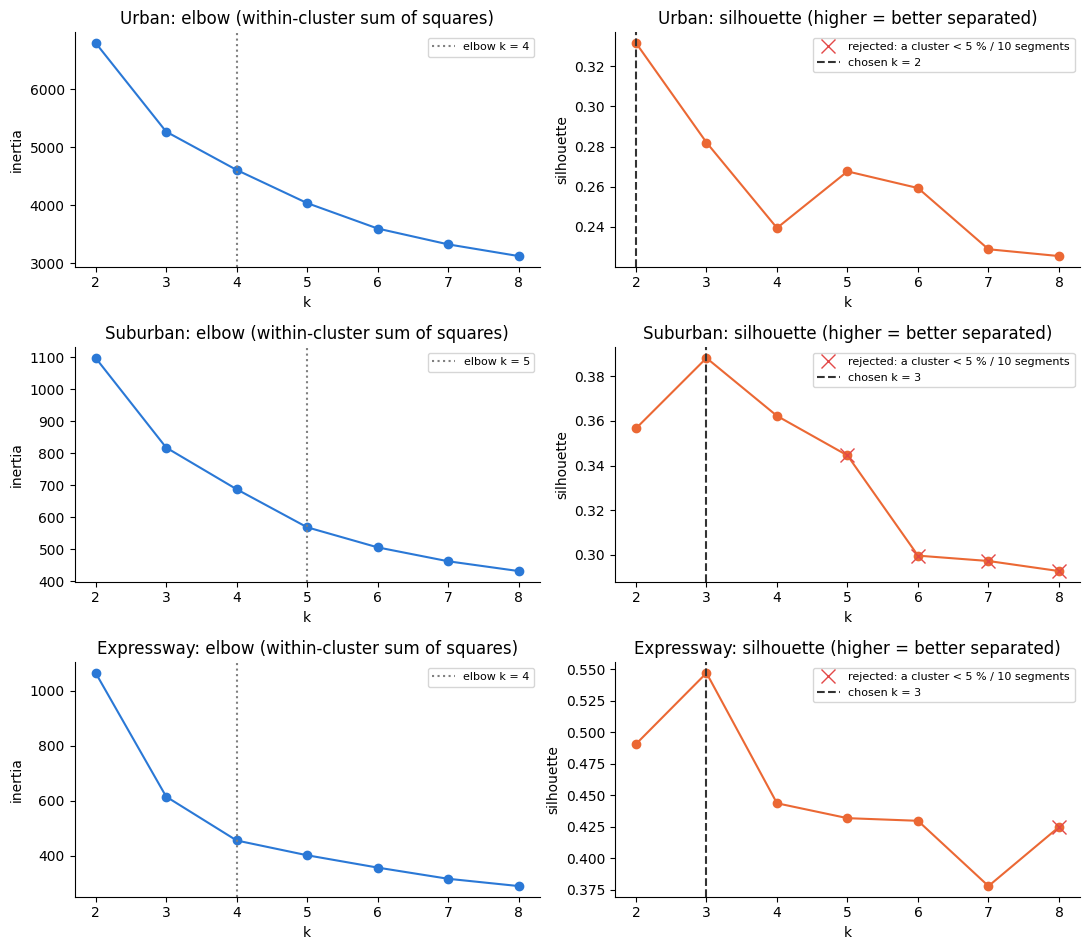

In [6]:
fig, axes = plt.subplots(len(envs), 2, figsize=(11, 3.2 * len(envs)), squeeze=False)
for row, e in zip(axes, envs):
    t = k_table[k_table["environment"] == e]
    r = results[e]
    row[0].plot(t["k"], t["inertia"], "o-", color="#2a78d6")
    row[0].axvline(r["k_elbow"], color="0.5", ls=":", label=f"elbow k = {r['k_elbow']}")
    row[0].set(title=f"{e}: elbow (within-cluster sum of squares)", xlabel="k", ylabel="inertia")
    row[1].plot(t["k"], t["silhouette"], "o-", color="#eb6834")
    bad = t[~t["acceptable"]]
    row[1].plot(bad["k"], bad["silhouette"], "x", color="#e34948", ms=10, label="rejected: a cluster < 5 % / 10 segments")
    row[1].axvline(r["k"], color="0.2", ls="--", label=f"chosen k = {r['k']}")
    row[1].set(title=f"{e}: silhouette (higher = better separated)", xlabel="k", ylabel="silhouette")
    for ax in row:
        ax.legend(fontsize=8)
        ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "k_selection.png", dpi=150)
plt.show()

In [7]:
def silhouette_meaning(s):
    # Kaufman & Rousseeuw (1990) rule of thumb
    return ("strong" if s > 0.7 else "reasonable" if s > 0.5 else "weak" if s > 0.25 else "no substantial structure")

quality = pd.DataFrame({e: {
    "segments": r["n"], "k": r["k"], "elbow_k": r["k_elbow"],
    "silhouette": round(r["silhouette"], 3), "structure": silhouette_meaning(r["silhouette"]),
    "davies_bouldin": round(r["davies_bouldin"], 3),
    "stability_ARI_bootstrap": round(r["ari_bootstrap_mean"], 3),
    "stability_ARI_worst": round(r["ari_bootstrap_min"], 3),
    "stability_ARI_seeds": round(r["ari_seeds"], 3),
    "stable": "yes" if r["ari_bootstrap_mean"] >= CFG["stable_ari"] else "no",
    "ARI_without_outlier_clipping": round(r["ari_without_clipping"], 3),
    "smallest_cluster": int(np.bincount(r["labels"])[1:].min()),
} for e, r in results.items()}).T
quality.to_csv(REPORT_DIR / "cluster_quality.csv")
print("Cluster quality per environment:")
quality

Cluster quality per environment:


,segments,k,elbow_k,silhouette,structure,davies_bouldin,stability_ARI_bootstrap,stability_ARI_worst,stability_ARI_seeds,stable,ARI_without_outlier_clipping,smallest_cluster
Urban,734,2,4,0.332,weak,1.272,0.964,0.907,1.0,yes,0.994,218
Suburban,127,3,5,0.388,weak,1.097,0.983,0.955,1.0,yes,1.0,22
Expressway,160,3,4,0.547,reasonable,0.646,1.0,1.0,1.0,yes,1.0,35


In [8]:
show = ["mean_speed_kmh", "max_speed_kmh", "std_speed_kmh", "std_accel_ms2", "rpa_ms2", "idle_share",
        "cruise_share", "stops_per_min", "duration_s", "distance_km"]
m = features.merge(clusters[["seg_uid", "cluster_id", "silhouette"]], on="seg_uid")
summary = m.groupby(["environment", "cluster_id"]).agg(
    segments=("seg_uid", "count"), hours=("duration_s", lambda s: s.sum() / 3600),
    km=("distance_km", "sum"), mean_silhouette=("silhouette", "mean"),
    **{f"median_{c}": (c, "median") for c in show})
summary.insert(1, "share_of_env_%", (100 * summary["segments"] /
                                     summary.groupby(level=0)["segments"].transform("sum")).round(1))
summary = summary.round(3)
summary.to_csv(REPORT_DIR / "cluster_summary.csv")
print("Cluster summary (medians in real units; clusters numbered from slowest to fastest within each environment):")
summary

Cluster summary (medians in real units; clusters numbered from slowest to fastest within each environment):


segments  share_of_env_%   hours        km  mean_silhouette  median_mean_speed_kmh  median_max_speed_kmh  median_std_speed_kmh  median_std_accel_ms2  median_rpa_ms2  median_idle_share  \
environment cluster_id                                                                                                                                                                                            
Expressway  EXP-C1            35            21.9   0.754    11.774            0.589                 14.902                38.095                17.106                 0.431           0.178              0.538   
            EXP-C2            36            22.5   0.457    15.153            0.616                 33.417                40.759                 8.570                 0.476           0.061              0.000   
            EXP-C3            89            55.6  15.094  1221.595            0.503                 81.280                94.459                17.677                 0.264           0.048              0.000   
Suburban    SUB-C1            22            17.3   0.255     2.375            0.169                  9.104                34.462                10.686                 0.521           0.351              0.557   
            SUB-C2            67            52.8   1.345    31.922            0.366                 25.102                41.670                 9.777                 0.435           0.133              0.000   
            SUB-C3            38            29.9   0.411    10.835            0.555                 26.596                52.345                20.538                 0.838           0.374              0.274   
Urban       URB-C1           218            29.7   2.956    38.228            0.249                 12.636                34.742                12.053                 0.812           0.293              0.358   
            URB-C2           516            70.3  22.514   515.757            0.367                 22.539                40.805                11.572                 0.463           0.142              0.090   

                        median_cruise_share  median_stops_per_min  median_duration_s  median_distance_km  
environment cluster_id                                                                                    
Expressway  EXP-C1                    0.244                 0.760               79.0               0.304  
            EXP-C2                    0.500                 0.000               49.0               0.461  
            EXP-C3                    0.749                 0.000              677.0              15.492  
Suburban    SUB-C1                    0.068                 1.532               41.0               0.098  
            SUB-C2                    0.350                 0.000               69.0               0.477  
            SUB-C3                    0.069                 1.538               39.0               0.291  
Urban       URB-C1                    0.076                 1.463               43.0               0.157  
            URB-C2                    0.318                 0.463              123.0               0.715

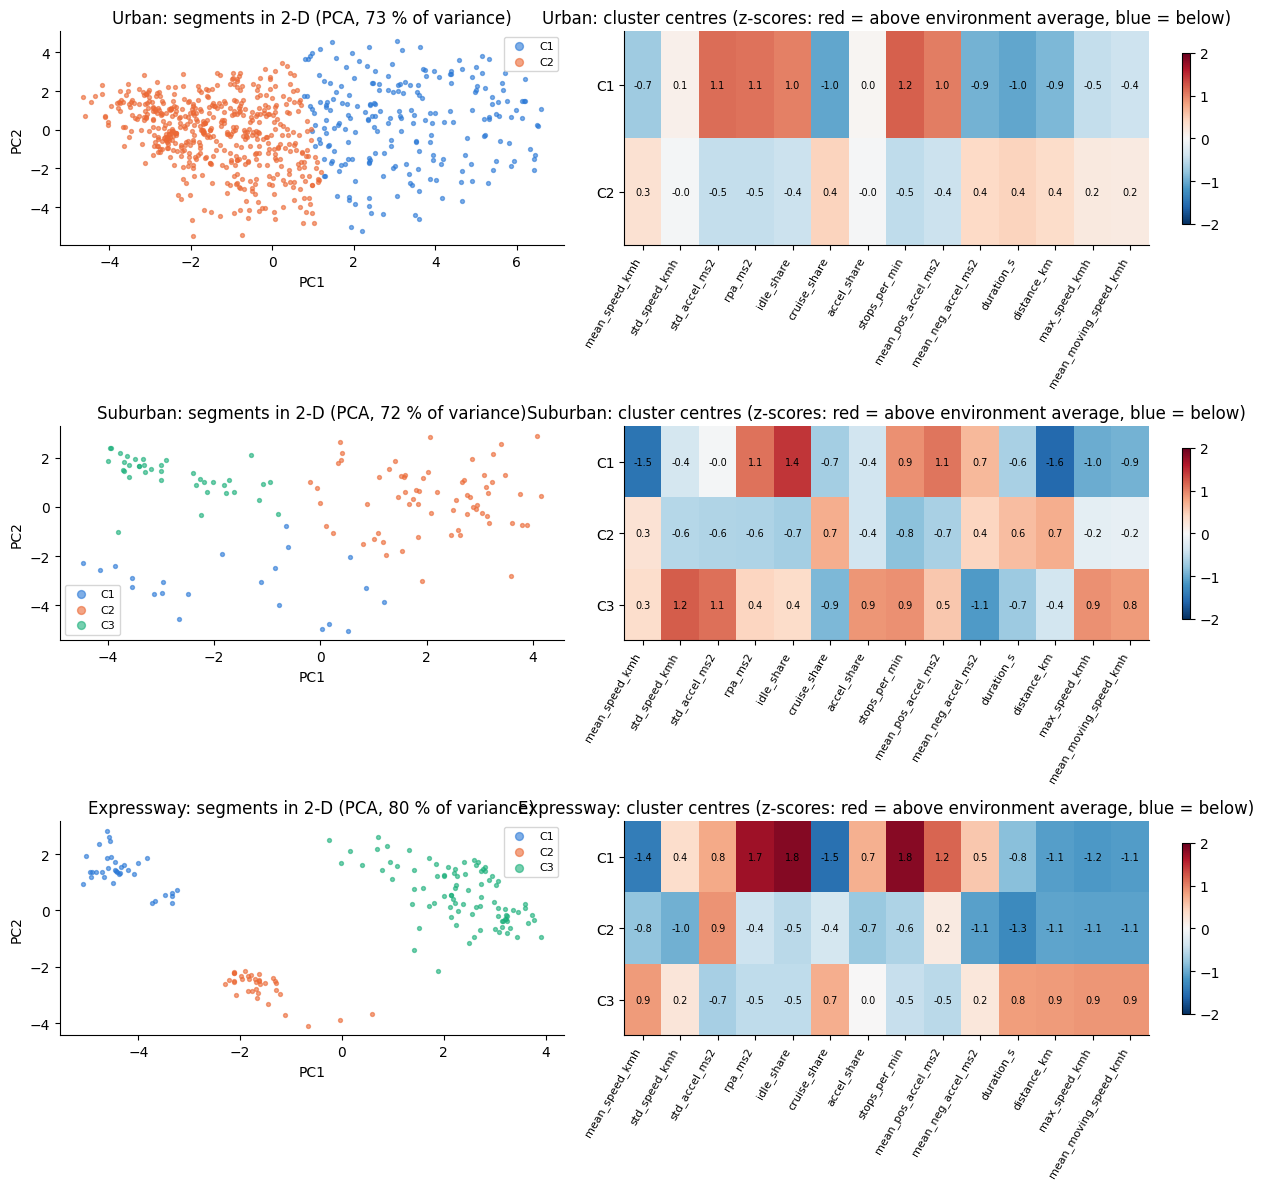

In [9]:
fig, axes = plt.subplots(len(envs), 2, figsize=(13, 4 * len(envs)), squeeze=False,
                         gridspec_kw={"width_ratios": [1, 1.3]})
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100", "#e34948", "#52514e", "#e87ba4"]
for row, e in zip(axes, envs):
    r = results[e]
    pca = PCA(n_components=2).fit(r["Z"])
    P = pca.transform(r["Z"])
    for c in np.unique(r["labels"]):
        row[0].scatter(P[r["labels"] == c, 0], P[r["labels"] == c, 1], s=8, alpha=0.6, color=palette[c - 1], label=f"C{c}")
    row[0].set(title=f"{e}: segments in 2-D (PCA, {100 * pca.explained_variance_ratio_.sum():.0f} % of variance)",
               xlabel="PC1", ylabel="PC2")
    row[0].legend(fontsize=8, markerscale=2)
    im = row[1].imshow(r["centers"], cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    row[1].set_yticks(range(r["k"]), [f"C{c}" for c in range(1, r["k"] + 1)])
    row[1].set_xticks(range(len(FEATS)), FEATS, rotation=60, ha="right", fontsize=8)
    for i in range(r["k"]):
        for j in range(len(FEATS)):
            row[1].text(j, i, f"{r['centers'][i, j]:.1f}", ha="center", va="center", fontsize=7)
    row[1].set_title(f"{e}: cluster centres (z-scores: red = above environment average, blue = below)")
    fig.colorbar(im, ax=row[1], shrink=0.8)
    for ax in row:
        ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "clusters_pca_and_centres.png", dpi=150)
plt.show()

In [10]:
# Candidate approach check: ONE clustering of all environments together.
# If its clusters simply reproduce the environments, a global clustering cannot find patterns
# INSIDE an environment - which is why clustering is done per environment.
allf = features[features["environment"].isin(envs)].reset_index(drop=True)
Zg, _ = prepare(allf)
tg = evaluate_k(Zg)
kg, _ = choose_k(tg)
lg = fit_kmeans(Zg, kg).labels_ + 1
ct = pd.crosstab(allf["environment"], lg, rownames=["environment"], colnames=["global cluster"])
purity = ct.max(axis=0).sum() / ct.values.sum()
ari_env = adjusted_rand_score(allf["environment"], lg)
print(f"Global K-Means (all environments together): k = {kg}, silhouette {tg.loc[tg['k'] == kg, 'silhouette'].iat[0]:.3f}")
print(f"Agreement of global clusters with the environment labels: ARI = {ari_env:.2f}, cluster purity = {100 * purity:.0f} %")
pd.DataFrame({"k": [kg], "ARI_with_environment": [round(ari_env, 3)], "purity_%": [round(100 * purity, 1)]}).to_csv(
    REPORT_DIR / "global_clustering_check.csv", index=False)
ct

Global K-Means (all environments together): k = 2, silhouette 0.517
Agreement of global clusters with the environment labels: ARI = 0.33, cluster purity = 81 %


global cluster,1,2
environment,,
Expressway,71,89
Suburban,127,0
Urban,734,0


In [11]:
checks = {}
usable = features[features["environment"].isin(envs)]
checks["every segment of a clustered environment has exactly one cluster"] = (
    len(clusters) == len(usable) and clusters["seg_uid"].is_unique and set(clusters["seg_uid"]) == set(usable["seg_uid"]))
checks["no identifiers, labels or coordinates among clustering features"] = not (
    set(FEATS) & forbidden or any("lat" in c or "lon" in c for c in FEATS))
checks["no missing values in the clustering matrix"] = all(not np.isnan(r["Z"]).any() for r in results.values())
checks["chosen k inside the tested range"] = all(CFG["k_range"][0] <= r["k"] <= CFG["k_range"][1] for r in results.values())
checks[f"every cluster >= {CFG['min_cluster_size']} segments"] = bool(
    clusters.groupby("cluster_id").size().min() >= CFG["min_cluster_size"])
checks["reproducible (refit with the same seed gives identical clusters)"] = all(
    adjusted_rand_score(r["labels"], fit_kmeans(r["Z"], r["k"]).labels_) == 1.0 for r in results.values())
checks["clusters numbered from slowest to fastest"] = all(
    np.all(np.diff([r["df"].loc[r["labels"] == c, "mean_speed_kmh"].mean() for c in range(1, r["k"] + 1)]) > 0)
    for r in results.values())
verification = pd.DataFrame({"result": ["PASS" if v else "CHECK" for v in checks.values()]}, index=checks.keys())
display(verification)

# stability is a RESULT, not a code check: reported separately
print("Stability (mean bootstrap ARI >= 0.8 = stable):",
      {e: f"{r['ari_bootstrap_mean']:.2f} ({'stable' if r['ari_bootstrap_mean'] >= CFG['stable_ari'] else 'NOT stable'})"
       for e, r in results.items()})

model = {"features": FEATS, "log_features": CFG["log_features"], "clip_z": CFG["clip_z"],
         "per_environment": {e: {"k": r["k"], "scaler_mean": r["scaler_mean"], "scaler_scale": r["scaler_scale"],
                                 "centres_z": r["centers"].round(4).tolist()} for e, r in results.items()}}
_ = (REPORT_DIR / "kmeans_model.json").write_text(json.dumps(model, indent=2))

,result
every segment of a clustered environment has exactly one cluster,PASS
"no identifiers, labels or coordinates among clustering features",PASS
no missing values in the clustering matrix,PASS
chosen k inside the tested range,PASS
every cluster >= 10 segments,PASS
reproducible (refit with the same seed gives identical clusters),PASS
clusters numbered from slowest to fastest,PASS


Stability (mean bootstrap ARI >= 0.8 = stable): {'Urban': '0.96 (stable)', 'Suburban': '0.98 (stable)', 'Expressway': '1.00 (stable)'}


In [12]:
print("STAGE 8 – K-MEANS CLUSTERING: KEY RESULTS")
print("-" * 60)
print(f"Clustering features ({len(FEATS)}): {', '.join(FEATS)}")
print("Approach: separate K-Means per environment; k by best silhouette among k without tiny clusters")
for e, r in results.items():
    sizes = np.bincount(r["labels"])[1:]
    print(f"  {e:10s}: {r['n']:4d} segments, k = {r['k']} (elbow {r['k_elbow']}), silhouette {r['silhouette']:.2f} "
          f"({silhouette_meaning(r['silhouette'])}), stability ARI {r['ari_bootstrap_mean']:.2f}, sizes {sizes.tolist()}")
for e in skipped:
    print(f"  {e:10s}: not clustered (too few segments)")
print(f"Global clustering check: ARI with environment labels = {ari_env:.2f} (high = global clusters just separate environments)")
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 8 – K-MEANS CLUSTERING: KEY RESULTS
------------------------------------------------------------
Clustering features (14): mean_speed_kmh, std_speed_kmh, std_accel_ms2, rpa_ms2, idle_share, cruise_share, accel_share, stops_per_min, mean_pos_accel_ms2, mean_neg_accel_ms2, duration_s, distance_km, max_speed_kmh, mean_moving_speed_kmh
Approach: separate K-Means per environment; k by best silhouette among k without tiny clusters
  Urban     :  734 segments, k = 2 (elbow 4), silhouette 0.33 (weak), stability ARI 0.96, sizes [218, 516]
  Suburban  :  127 segments, k = 3 (elbow 5), silhouette 0.39 (weak), stability ARI 0.98, sizes [22, 67, 38]
  Expressway:  160 segments, k = 3 (elbow 4), silhouette 0.55 (reasonable), stability ARI 1.00, sizes [35, 36, 89]
Global clustering check: ARI with environment labels = 0.33 (high = global clusters just separate environments)
Verification: all checks PASS
